# 05. Ewaluacja na zbiorze testowym, wyjaśnialność i analiza błędów

Modele końcowe uczono na całym zbiorze treningowym (5500 obrazów) z liczbą epok z walidacji
krzyżowej (`python -m src.train final ...`). Zbiór testowy został użyty **raz**, skryptem
`python -m src.evaluate`, który zapisał predykcje i metryki do `out/metrics/`. Ten notatnik
tylko wczytuje te pliki (oraz liczy mapy Grad-CAM dla wybranych obrazów).

Raportujemy dwa zbiory:
- **test** - oryginalny katalog `Testing` (1600 obrazów),
- **test_dedup** - test bez obrazów mających bliźniaka w treningu (pHash <= 4) i bez plików
  `aug` (806 obrazów, notatnik 01).

In [1]:
import sys
sys.path.insert(0, '..')

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_curve

from src.data import CLASSES, FIG_DIR, METRICS_DIR, ROOT, load_image
from src.gradcam import grad_cam, overlay
from src.train import DEVICE, load_trained

TAGS = {'cnn': 'CNN od zera', 'efficientnet_b0': 'EfficientNetB0', 'resnet50': 'ResNet50',
        'resnet50_tuned': 'ResNet50 (Optuna)'}
BEST = 'resnet50_tuned'
res = json.load(open(METRICS_DIR / 'test_metrics.json'))
preds = {t: pd.read_csv(METRICS_DIR / f'test_preds_{t}.csv') for t in TAGS}
P_COLS = [f'p_{c}' for c in CLASSES]

## 1. Porównanie modeli na teście (z 95% przedziałami ufności z bootstrapu)
Bootstrap: 1000 razy losujemy ze zwracaniem zbiór testowy tej samej wielkości i liczymy
metrykę; przedział to 2,5 i 97,5 percentyl wyników. Pokazuje, jak bardzo wynik zależy od tego,
które obrazy akurat trafiły do testu.

In [2]:
def fmt(r, key):
    lo, hi = r['ci95'][key]
    return f"{r['summary'][key]:.3f} [{lo:.3f}-{hi:.3f}]"

rows = []
for t, name in TAGS.items():
    for split in ['test', 'test_dedup']:
        r = res[t][split]
        rows.append({'model': name, 'zbiór': split, 'accuracy': fmt(r, 'accuracy'),
                     'macro-F1': fmt(r, 'macro_f1'), 'macro AUC': fmt(r, 'macro_auc'),
                     'macro czułość': round(r['summary']['macro_recall'], 3),
                     'macro swoistość': round(r['summary']['macro_specificity'], 3),
                     'ECE': round(r['ece'], 3)})
table_models = pd.DataFrame(rows)
table_models

,model,zbiór,accuracy,macro-F1,macro AUC,macro czułość,macro swoistość,ECE
0,CNN od zera,test,0.919 [0.906-0.932],0.918 [0.904-0.930],0.974 [0.968-0.980],0.919,0.973,0.031
1,CNN od zera,test_dedup,0.872 [0.850-0.895],0.822 [0.790-0.853],0.963 [0.954-0.971],0.904,0.962,0.070
2,EfficientNetB0,test,0.953 [0.943-0.963],0.952 [0.941-0.962],0.993 [0.990-0.995],0.953,0.984,0.036
3,EfficientNetB0,test_dedup,0.914 [0.896-0.933],0.874 [0.843-0.900],0.990 [0.986-0.993],0.942,0.975,0.067
4,ResNet50,test,0.949 [0.938-0.959],0.948 [0.936-0.958],0.991 [0.987-0.994],0.949,0.983,0.040
5,ResNet50,test_dedup,0.906 [0.886-0.926],0.866 [0.834-0.893],0.987 [0.982-0.991],0.934,0.972,0.077
6,ResNet50 (Optuna),test,0.957 [0.946-0.966],0.956 [0.945-0.965],0.989 [0.985-0.993],0.957,0.986,0.036
7,ResNet50 (Optuna),test_dedup,0.917 [0.898-0.935],0.886 [0.857-0.913],0.986 [0.981-0.990],0.945,0.976,0.071


## 2. Metryki per klasa dla najlepszego modelu
Czułość (recall) = TP / (TP + FN): jaki odsetek obrazów danej klasy model rozpoznał.
Swoistość = TN / (TN + FP) w układzie „ta klasa kontra reszta”: jaki odsetek obrazów innych
klas model poprawnie **nie** przypisał do tej klasy.

In [3]:
def per_class(tag, split):
    r = res[tag][split]
    out = pd.DataFrame(r['per_class']).set_index('klasa')
    for c in CLASSES:
        lo, hi = r['ci95'][f'czulosc_{c}']
        out.loc[c, 'czułość 95% CI'] = f'{lo:.3f}-{hi:.3f}'
        lo, hi = r['ci95'][f'swoistosc_{c}']
        out.loc[c, 'swoistość 95% CI'] = f'{lo:.3f}-{hi:.3f}'
    return out.round(3)

per_class(BEST, 'test')

,n,czulosc,swoistosc,precyzja,f1,auc,czułość 95% CI,swoistość 95% CI
klasa,,,,,,,,
glioma,400,0.832,1.000,1.000,0.909,0.965,0.792-0.866,1.000-1.000
meningioma,400,0.995,0.965,0.905,0.948,0.992,0.987-1.000,0.954-0.975
notumor,400,1.000,0.979,0.941,0.970,0.999,1.000-1.000,0.971-0.987
pituitary,400,1.000,0.998,0.995,0.998,1.000,1.000-1.000,0.996-1.000


In [4]:
per_class(BEST, 'test_dedup')

,n,czulosc,swoistosc,precyzja,f1,auc,czułość 95% CI,swoistość 95% CI
klasa,,,,,,,,
glioma,314,0.793,1.000,1.000,0.885,0.958,0.748-0.837,1.000-1.000
meningioma,147,0.986,0.939,0.784,0.873,0.986,0.965-1.000,0.920-0.957
notumor,47,1.000,0.967,0.653,0.790,0.998,1.000-1.000,0.954-0.979
pituitary,298,1.000,0.996,0.993,0.997,1.000,1.000-1.000,0.990-1.000


## 3. Macierze pomyłek

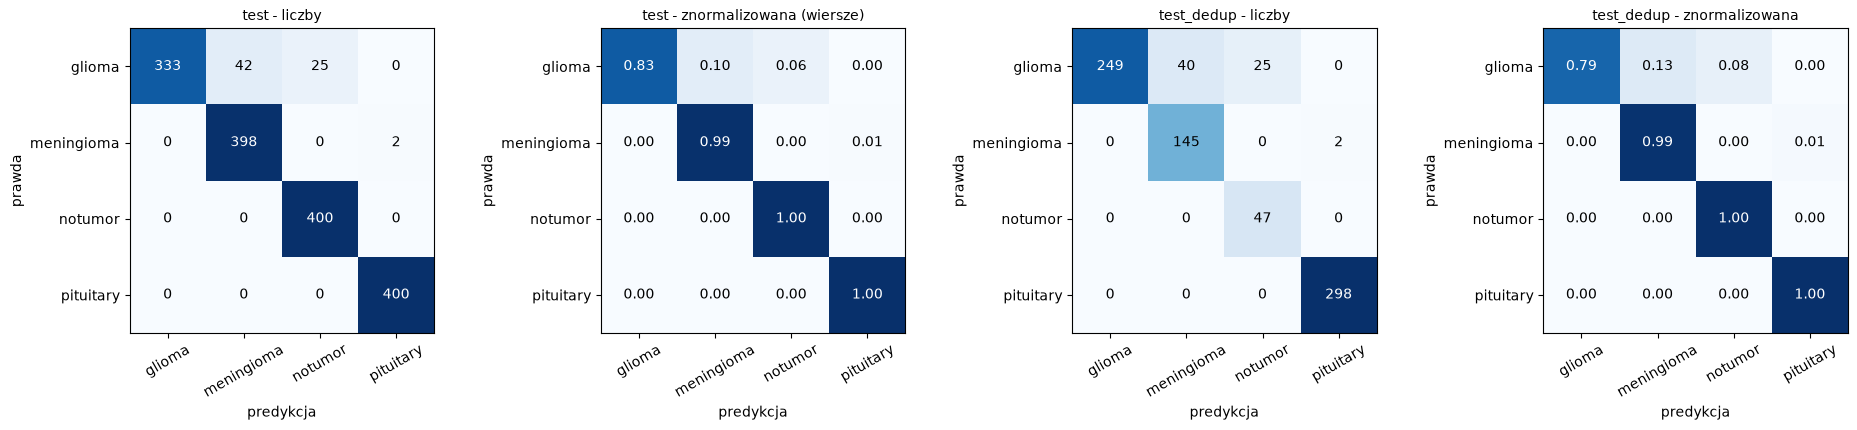

In [5]:
def plot_cm(ax, y, p, title, normalize=False):
    cm = confusion_matrix(y, p, labels=range(4))
    shown = cm / cm.sum(1, keepdims=True) if normalize else cm
    ax.imshow(shown, cmap='Blues')
    for i in range(4):
        for j in range(4):
            txt = f'{shown[i, j]:.2f}' if normalize else str(cm[i, j])
            ax.text(j, i, txt, ha='center', va='center', color='white' if shown[i, j] > shown.max() / 2 else 'black')
    ax.set_xticks(range(4), CLASSES, rotation=30)
    ax.set_yticks(range(4), CLASSES)
    ax.set_xlabel('predykcja')
    ax.set_ylabel('prawda')
    ax.set_title(title, fontsize=10)

d = preds[BEST]
dd = d[d.test_dedup]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
plot_cm(axes[0], d.label, d.pred, 'test - liczby')
plot_cm(axes[1], d.label, d.pred, 'test - znormalizowana (wiersze)', True)
plot_cm(axes[2], dd.label, dd.pred, 'test_dedup - liczby')
plot_cm(axes[3], dd.label, dd.pred, 'test_dedup - znormalizowana', True)
plt.tight_layout()
plt.savefig(FIG_DIR / 'test_macierze.png', dpi=150)
plt.show()

## 4. Krzywe ROC (klasa kontra reszta)
Krzywa ROC pokazuje czułość (TPR) względem 1 - swoistość (FPR) dla wszystkich progów
decyzyjnych na prawdopodobieństwie danej klasy. AUC = pole pod krzywą, czyli
prawdopodobieństwo, że losowy obraz tej klasy dostanie wyższy wynik niż losowy obraz innej klasy.

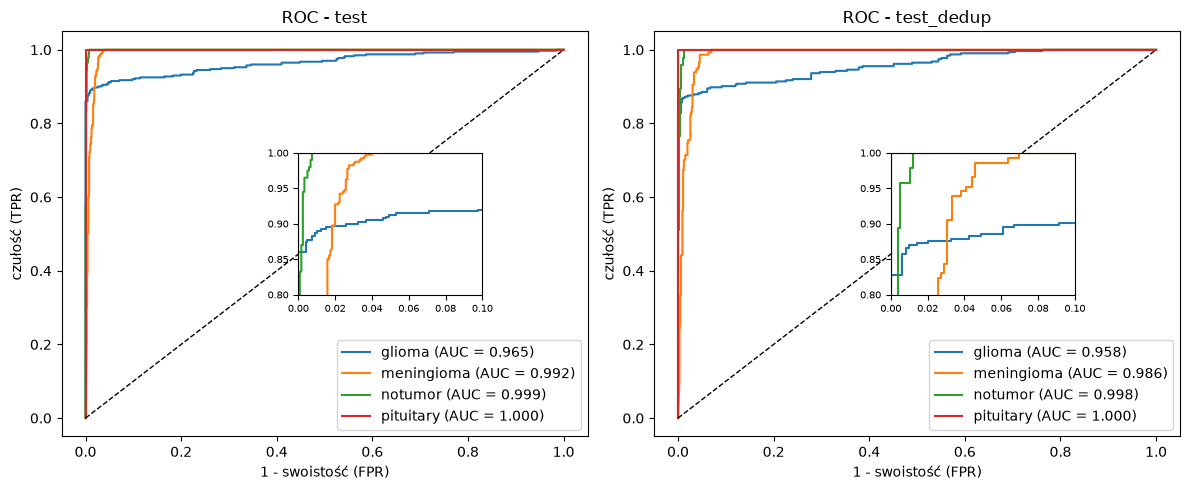

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, part) in zip(axes, [('test', d), ('test_dedup', dd)]):
    for k, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(part.label == k, part[f'p_{c}'])
        auc = [r for r in res[BEST][title]['per_class'] if r['klasa'] == c][0]['auc']
        ax.plot(fpr, tpr, label=f'{c} (AUC = {auc:.3f})')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlabel('1 - swoistość (FPR)')
    ax.set_ylabel('czułość (TPR)')
    ax.set_title(f'ROC - {title}')
    ax.legend(loc='lower right')
    # wstawka z powiększeniem lewego górnego rogu
    ins = ax.inset_axes([0.45, 0.35, 0.35, 0.35])
    for k, c in enumerate(CLASSES):
        fpr, tpr, _ = roc_curve(part.label == k, part[f'p_{c}'])
        ins.plot(fpr, tpr)
    ins.set_xlim(0, 0.1)
    ins.set_ylim(0.8, 1.0)
    ins.tick_params(labelsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'test_roc.png', dpi=150)
plt.show()

## 5. Kalibracja (czy „pewność” modelu oznacza trafność?)
Wykres niezawodności: obrazy dzielimy na przedziały według najwyższego prawdopodobieństwa
i porównujemy średnią pewność z odsetkiem trafnych odpowiedzi. ECE to średnia różnica
(ważona liczbą obrazów). Model dobrze skalibrowany leży na przekątnej.

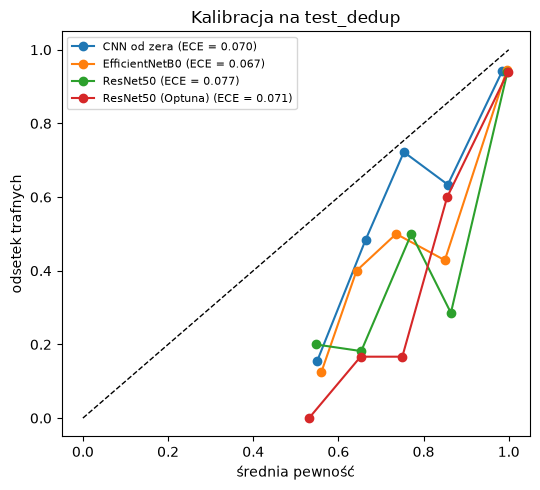

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 5))
bins = np.linspace(0, 1, 11)
for t in TAGS:
    part = preds[t][preds[t].test_dedup]
    conf = part[P_COLS].to_numpy().max(1)
    correct = (part.pred == part.label).to_numpy()
    xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= 5:
            xs.append(conf[m].mean())
            ys.append(correct[m].mean())
    ax.plot(xs, ys, 'o-', label=f"{TAGS[t]} (ECE = {res[t]['test_dedup']['ece']:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('średnia pewność')
ax.set_ylabel('odsetek trafnych')
ax.set_title('Kalibracja na test_dedup')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'test_kalibracja.png', dpi=150)
plt.show()

## 6. Grad-CAM
Grad-CAM (wykład 5) liczy gradient wyniku klasy po aktywacjach ostatniej warstwy
konwolucyjnej, uśrednia go w każdym kanale (waga kanału) i sumuje ważone aktywacje.
Wynik (po ReLU) to mapa o niskiej rozdzielczości (7x7 dla EfficientNetB0 i ResNet50,
14x14 dla CNN), skalowana do rozmiaru obrazu. Implementacja: `src/gradcam.py` (hooki PyTorch).

Poniżej po 2 trafne i 2 błędne predykcje z każdej klasy (test_dedup), z mapą dla klasy
przewidzianej. Dla `notumor` i `pituitary` nie ma błędów na test_dedup, więc te wiersze mają
tylko trafne przykłady.

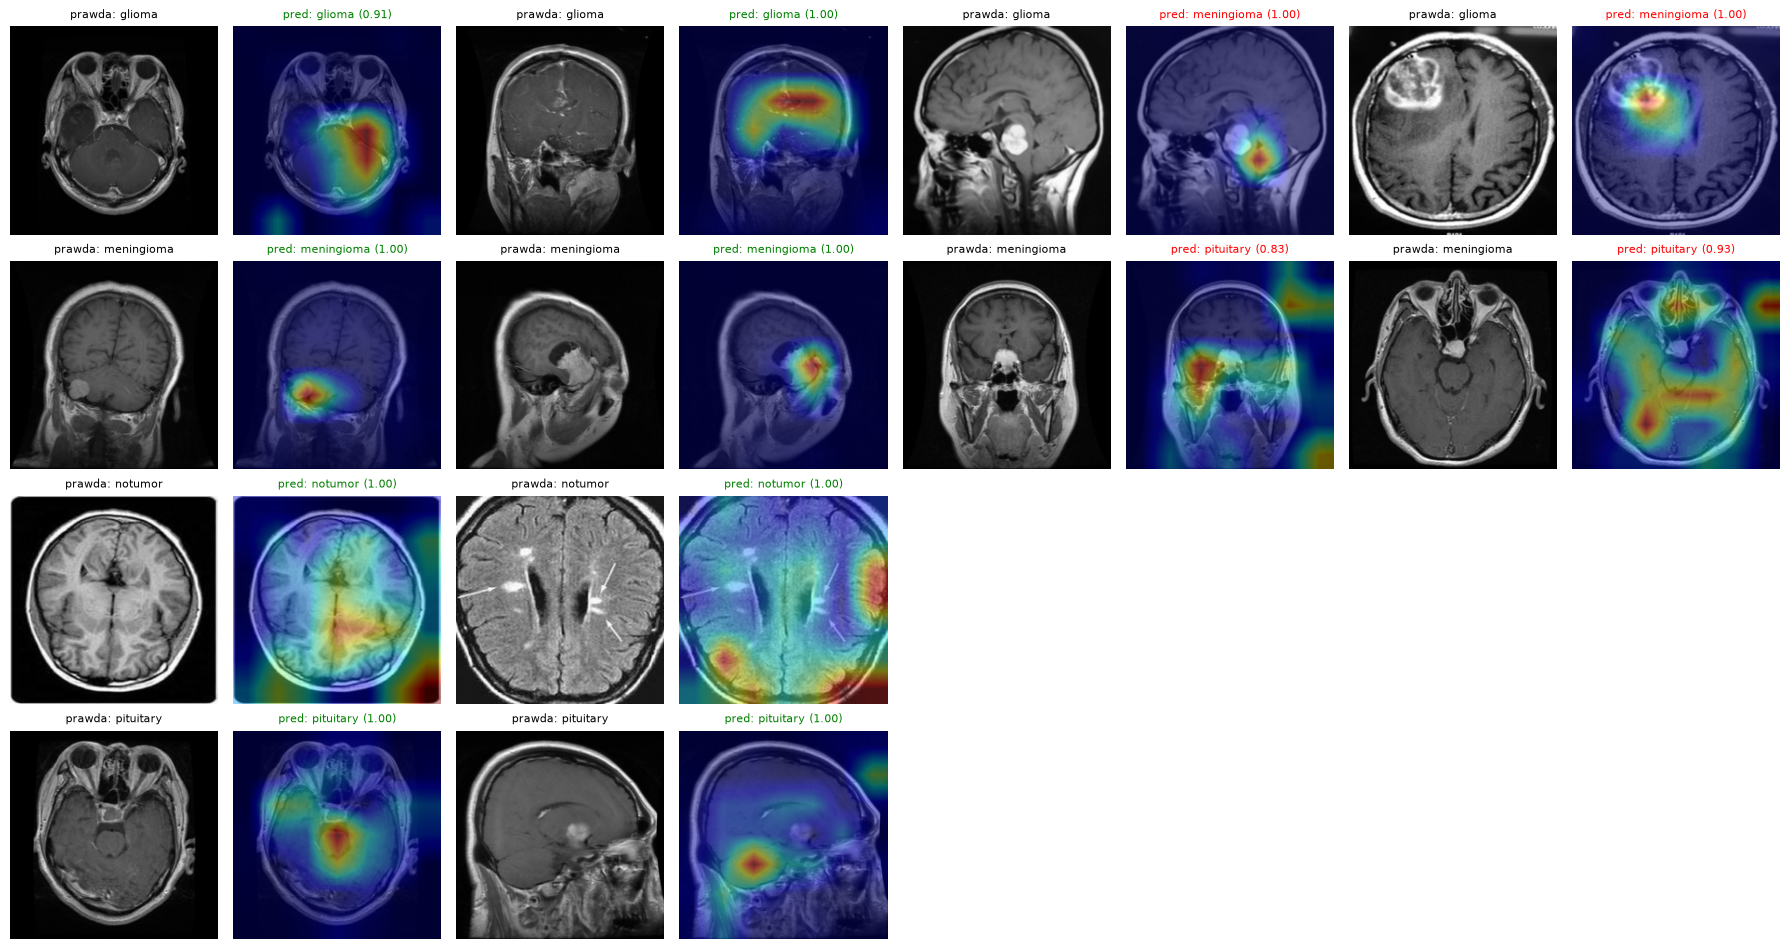

In [8]:
model = load_trained(BEST)

def cam_for(path, target=None, m=model):
    img = load_image(ROOT / path)
    x = torch.tensor(img).float().div(255)[None, None].to(DEVICE)
    cam, pred, probs = grad_cam(m, x, target)
    return img, cam, pred, probs

rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 8, figsize=(18, 9.6))
for r, c in enumerate(CLASSES):
    part = dd[dd.label == r]
    ok = part[part.pred == r].path.to_numpy()
    bad = part[part.pred != r].path.to_numpy()
    chosen = list(rng.choice(ok, 2, replace=False)) + list(rng.choice(bad, min(2, len(bad)), replace=False))
    for k, p in enumerate(chosen):
        img, cam, pred, probs = cam_for(p)
        axes[r, 2 * k].imshow(img, cmap='gray')
        axes[r, 2 * k + 1].imshow(overlay(img, cam))
        color = 'green' if pred == r else 'red'
        axes[r, 2 * k].set_title(f'prawda: {c}', fontsize=8)
        axes[r, 2 * k + 1].set_title(f'pred: {CLASSES[pred]} ({probs[pred]:.2f})', fontsize=8, color=color)
for a in axes.ravel():
    a.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'gradcam_galeria.png', dpi=110)
plt.show()

### Gdzie patrzy model - ocena ilościowa
Ręczne oglądanie kilkunastu map łatwo prowadzi do nadinterpretacji (wykład 5, slajd 21).
Dlatego liczymy dla wszystkich obrazów test_dedup, jaka część „masy” mapy Grad-CAM leży:
- na **tle** (piksele ciemniejsze niż 20, poza głową),
- w **pasie brzegowym** obrazu (zewnętrzne 10% szerokości - tam są ramki, napisy, krawędzie kadru).

Tło zajmuje 36-49% obrazu (zależnie od klasy, kolumna `udzial_tla_w_obrazie`), a pas brzegowy
35% obrazu - tyle masy miałaby tam mapa równomierna.

In [9]:
rows = []
for p, y, pr in zip(dd.path, dd.label, dd.pred):
    img, cam, _, _ = cam_for(p)
    total = cam.sum() + 1e-8
    border = np.ones_like(cam, dtype=bool)
    border[22:-22, 22:-22] = False
    rows.append({'klasa': CLASSES[y], 'trafna': y == pr,
                 'udzial_tla_w_obrazie': (img < 20).mean(),
                 'masa_na_tle': cam[img < 20].sum() / total,
                 'masa_na_brzegu': cam[border].sum() / total})
cam_stats = pd.DataFrame(rows)
cam_stats.to_csv(METRICS_DIR / 'gradcam_stats.csv', index=False)
cam_stats.groupby(['klasa']).mean(numeric_only=True).round(3)

,trafna,udzial_tla_w_obrazie,masa_na_tle,masa_na_brzegu
klasa,,,,
glioma,0.793,0.483,0.132,0.079
meningioma,0.986,0.494,0.116,0.064
notumor,1.000,0.464,0.366,0.238
pituitary,1.000,0.359,0.168,0.150


In [10]:
cam_stats.groupby('trafna')[['masa_na_tle', 'masa_na_brzegu']].mean().round(3)

,masa_na_tle,masa_na_brzegu
trafna,,
False,0.174,0.166
True,0.154,0.107


### Porównanie z mapą saliency (gradient po pikselach)
Wykład 5 (slajd 20) zwraca uwagę, że różne metody wyjaśniania potrafią dawać różne wyniki
dla tego samego modelu. Porównujemy Grad-CAM z najprostszą mapą saliency
(|gradient wyniku klasy po pikselach wejścia|) dla kilku obrazów.

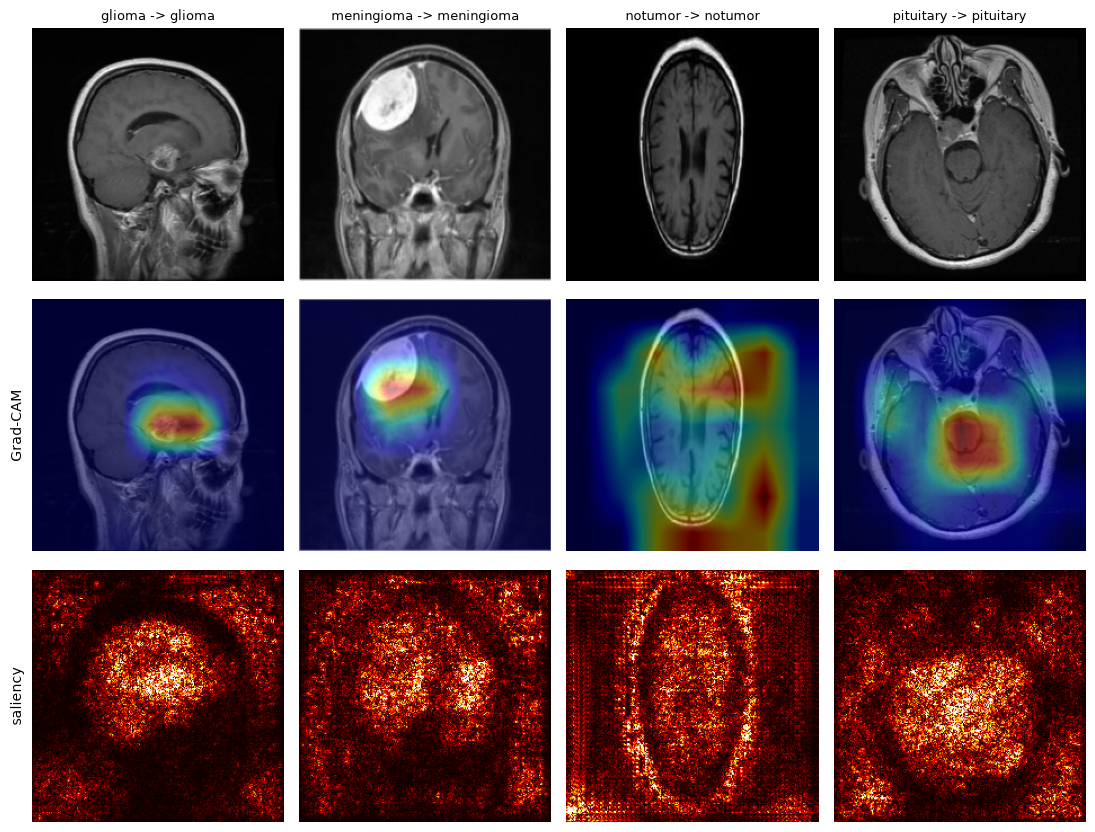

In [11]:
def saliency(path, m=model):
    img = load_image(ROOT / path)
    x = torch.tensor(img).float().div(255)[None, None].to(DEVICE).requires_grad_(True)
    logits = m(x)
    k = int(logits.argmax())
    logits[0, k].backward()
    s = x.grad.abs()[0, 0].cpu().numpy()
    return img, s / (s.max() + 1e-8)

sample = dd.groupby('label').sample(1, random_state=3).path.to_numpy()
fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))
for j, p in enumerate(sample):
    img, cam, pred, probs = cam_for(p)
    _, sal = saliency(p)
    axes[0, j].imshow(img, cmap='gray')
    axes[0, j].set_title(f'{CLASSES[dd.label[dd.path == p].iloc[0]]} -> {CLASSES[pred]}', fontsize=9)
    axes[1, j].imshow(overlay(img, cam))
    axes[2, j].imshow(np.clip(sal * 4, 0, 1), cmap='hot')
for a in axes.ravel():
    a.axis('off')
axes[1, 0].text(-20, 112, 'Grad-CAM', rotation=90, va='center')
axes[2, 0].text(-20, 112, 'saliency', rotation=90, va='center')
plt.tight_layout()
plt.savefig(FIG_DIR / 'gradcam_vs_saliency.png', dpi=110)
plt.show()

**Co widać na mapach Grad-CAM?**
- Dla glejaków, oponiaków i guzów przysadki mapy w większości trafnych przypadków wskazują
  zmianę (guz) albo okolicę siodła tureckiego (przysadka), czyli obszar zgodny z intuicją kliniczną.
- Dla `notumor` mapa jest rozlana po całym obrazie, a często także na tle i brzegach kadru.
  Model nie „sprawdza”, czy guza brak, tylko rozpoznaje ogólny wygląd obrazu. Ilościowo: dla
  `notumor` ok. 37% masy mapy leży na tle i ok. 24% w pasie brzegowym. Dla klas z guzem jest to
  12-17% i 6-15%, choć tło zajmuje 36-49% obrazu, a pas brzegowy 35%. Mapy dla klas z guzem
  są więc skupione na głowie, a dla `notumor` są bliskie rozkładowi równomiernemu.
- Mapa saliency wskazuje podobne obszary dla klas z guzem, ale jest dużo bardziej zaszumiona
  (rozdzielczość pikseli zamiast 7x7). Dla obrazu `notumor` wyraźnie podkreśla ramkę i krawędzie
  kadru, co wspiera hipotezę, że cechy techniczne obrazu (kadrowanie, źródło) wpływają na decyzję.
  Obie metody nie są w pełni zgodne (wykład 5, slajd 20), więc żadnej nie traktujemy jako dowodu.
- Ostrożnie z wnioskami (slajd 21): mapa pokazuje, co koreluje z wynikiem, a nie dlaczego
  model podjął decyzję. Ładna mapa na guzie nie oznacza, że model rozumie typ guza - patrz analiza błędów.

## 7. Analiza błędów

In [12]:
errors = d[d.pred != d.label].copy()
errors['para'] = errors.cls + ' -> ' + errors.pred.map(dict(enumerate(CLASSES)))
errors['pewnosc'] = errors[P_COLS].to_numpy().max(1)
print('błędy na teście:', len(errors), 'z', len(d), '| w tym w test_dedup:', int(errors.test_dedup.sum()))
errors.groupby('para').size().sort_values(ascending=False)

błędy na teście: 69 z 1600 | w tym w test_dedup: 67


para
glioma -> meningioma       42
glioma -> notumor          25
meningioma -> pituitary     2
dtype: int64

Czy błędy mają związek z cechami zauważonymi w EDA? Sprawdzamy rozdzielczość oryginału,
podobieństwo do obrazów treningowych i duplikaty z inną etykietą.

In [13]:
dup = pd.read_csv(METRICS_DIR / 'duplicates.csv', dtype={'phash': str, 'md5': str}).set_index('path')
train_cls = dup.cls
d2 = d.copy()
d2['blad'] = d2.pred != d2.label
d2['min_dist_train'] = dup.loc[d2.path, 'min_dist_train'].to_numpy()
d2['klasa_najblizszego'] = train_cls.loc[dup.loc[d2.path, 'nearest_train']].to_numpy()
d2['blizniak_innej_klasy'] = (d2.min_dist_train <= 4) & (d2.klasa_najblizszego != d2.cls)
d2['rozmiar_512'] = [Image.open(ROOT / p).size == (512, 512) for p in d2.path]
print('odsetek błędów wśród obrazów z bliźniakiem w treningu tej samej klasy:',
      round(d2[(d2.min_dist_train <= 4) & ~d2.blizniak_innej_klasy].blad.mean(), 4))
print('odsetek błędów wśród obrazów bez bliźniaka w treningu:', round(d2[d2.min_dist_train > 4].blad.mean(), 4))
print('obrazy z bliźniakiem INNEJ klasy w treningu:', int(d2.blizniak_innej_klasy.sum()),
      '| w tym błędy:', int(d2[d2.blizniak_innej_klasy].blad.sum()))
d2.groupby(['cls', 'rozmiar_512']).blad.agg(['mean', 'size']).round(3)

odsetek błędów wśród obrazów z bliźniakiem w treningu tej samej klasy: 0.0
odsetek błędów wśród obrazów bez bliźniaka w treningu: 0.0756
obrazy z bliźniakiem INNEJ klasy w treningu: 8 | w tym błędy: 2


mean  size
cls        rozmiar_512             
glioma     False        0.868    76
           True         0.003   324
meningioma False        0.000   117
           True         0.007   283
notumor    False        0.000   397
           True         0.000     3
pituitary  False        0.000     8
           True         0.000   392

Błędy skupiają się w obrazach glejaków o rozmiarze innym niż 512x512. Porównajmy, ile takich
obrazów (czyli obrazów spoza zbioru figshare) jest w każdej klasie w treningu i w teście.

In [14]:
train_paths = dup[(dup.split == 'Training') & ~dup.aug].index
src = pd.DataFrame({'path': train_paths, 'cls': dup.loc[train_paths, 'cls'].to_numpy()})
src['rozmiar_512'] = [Image.open(ROOT / p).size == (512, 512) for p in src.path]
zrodlo = pd.DataFrame({
    'trening: nie 512x512': src[~src.rozmiar_512].groupby('cls').size(),
    'test: nie 512x512': d2[~d2.rozmiar_512].groupby('cls').size(),
    'test: błędy wśród nie 512x512': d2[~d2.rozmiar_512].groupby('cls').blad.sum(),
    'test: błędy wśród 512x512': d2[d2.rozmiar_512].groupby('cls').blad.sum(),
    'test: 512x512': d2[d2.rozmiar_512].groupby('cls').size(),
}).reindex(CLASSES).fillna(0).astype(int)
zrodlo.to_csv(METRICS_DIR / 'bledy_zrodlo.csv')
zrodlo

,trening: nie 512x512,test: nie 512x512,test: błędy wśród nie 512x512,test: błędy wśród 512x512,test: 512x512
cls,,,,,
glioma,0,76,66,1,324
meningioma,133,117,0,2,283
notumor,1383,397,0,0,3
pituitary,72,8,0,0,392


### Najbardziej „pewne” błędy

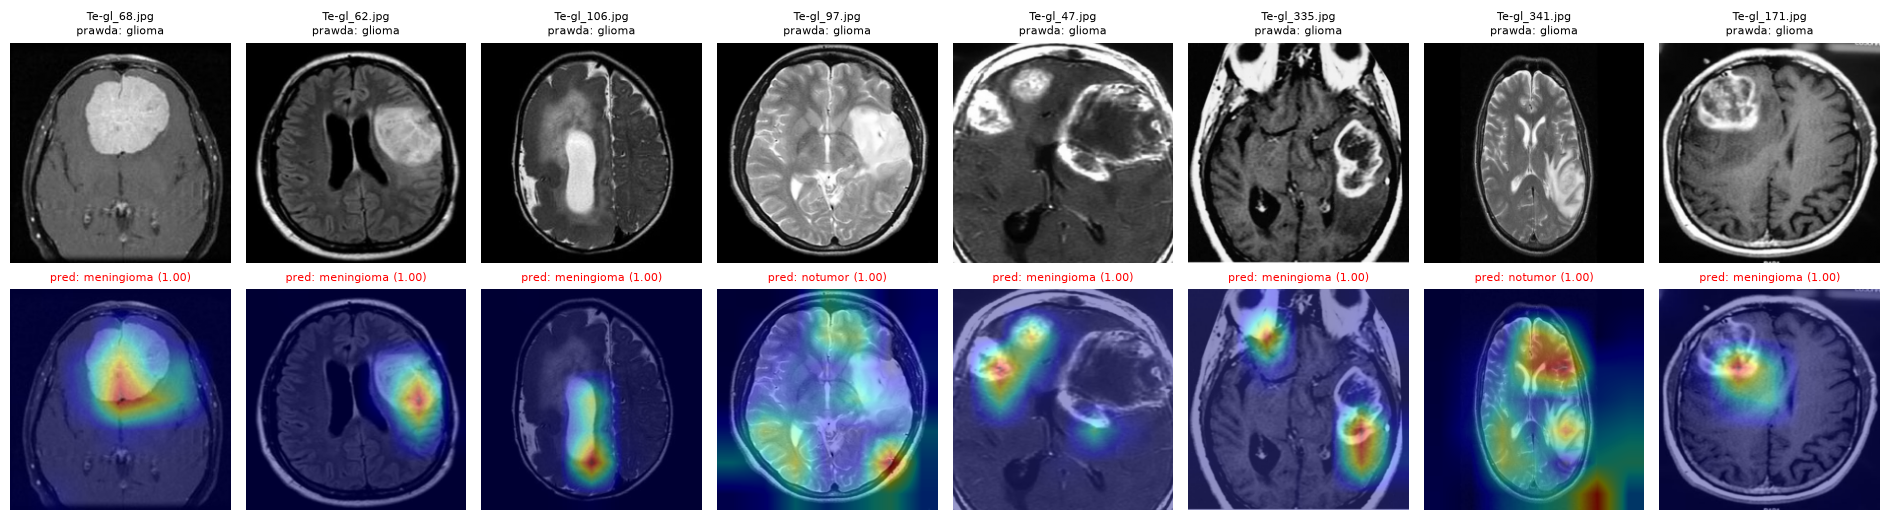

,path,para,pewnosc,test_dedup
365,data/raw/Testing/glioma/Te-gl_68.jpg,glioma -> meningioma,1.000000,False
359,data/raw/Testing/glioma/Te-gl_62.jpg,glioma -> meningioma,1.000000,True
8,data/raw/Testing/glioma/Te-gl_106.jpg,glioma -> meningioma,1.000000,True
397,data/raw/Testing/glioma/Te-gl_97.jpg,glioma -> notumor,0.999999,True
342,data/raw/Testing/glioma/Te-gl_47.jpg,glioma -> meningioma,0.999999,True
262,data/raw/Testing/glioma/Te-gl_335.jpg,glioma -> meningioma,0.999996,True
269,data/raw/Testing/glioma/Te-gl_341.jpg,glioma -> notumor,0.999992,True
80,data/raw/Testing/glioma/Te-gl_171.jpg,glioma -> meningioma,0.999988,True


In [15]:
worst = errors.sort_values('pewnosc', ascending=False).head(8)
fig, axes = plt.subplots(2, 8, figsize=(19, 5.4))
for j, (_, row) in enumerate(worst.iterrows()):
    img, cam, pred, probs = cam_for(row.path)
    axes[0, j].imshow(img, cmap='gray')
    axes[0, j].set_title(f"{row.path.split('/')[-1]}\nprawda: {row.cls}", fontsize=8)
    axes[1, j].imshow(overlay(img, cam))
    axes[1, j].set_title(f'pred: {CLASSES[pred]} ({probs[pred]:.2f})', fontsize=8, color='red')
for a in axes.ravel():
    a.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'bledy_pewne.png', dpi=110)
plt.show()
worst[['path', 'para', 'pewnosc', 'test_dedup']]

### Błędy glejak <-> oponiak

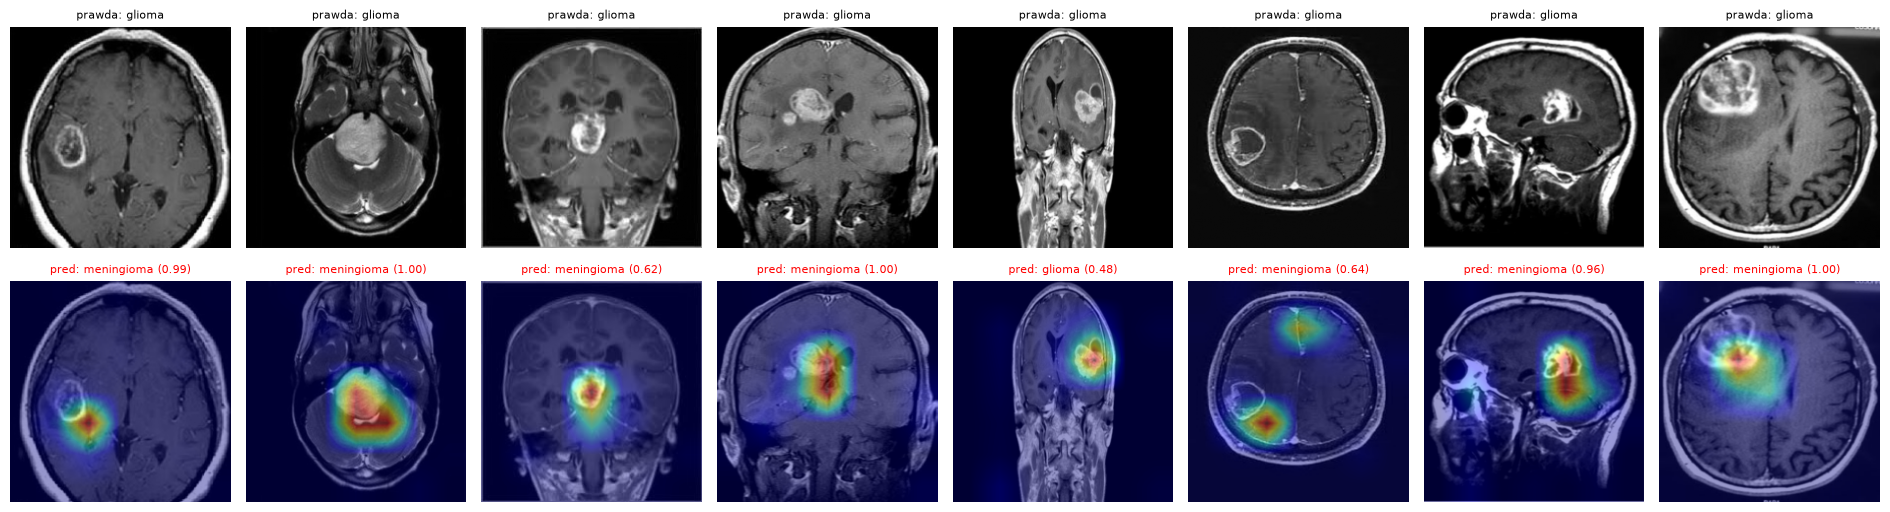

In [16]:
gm = errors[errors.para.isin(['glioma -> meningioma', 'meningioma -> glioma'])]
show = gm.sample(min(8, len(gm)), random_state=0)
fig, axes = plt.subplots(2, 8, figsize=(19, 5.4))
for j, (_, row) in enumerate(show.iterrows()):
    img, cam, pred, probs = cam_for(row.path)
    axes[0, j].imshow(img, cmap='gray')
    axes[0, j].set_title(f'prawda: {row.cls}', fontsize=8)
    axes[1, j].imshow(overlay(img, cam))
    axes[1, j].set_title(f'pred: {CLASSES[pred]} ({probs[pred]:.2f})', fontsize=8, color='red')
for a in axes.ravel():
    a.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'bledy_glioma_meningioma.png', dpi=110)
plt.show()

**Wnioski z analizy błędów**
1. **Wyciek zawyża oryginalny test.** Wśród obrazów, które mają w treningu bliźniaka tej samej
   klasy, model nie pomylił się ani razu, a wśród obrazów bez bliźniaka myli się w 7,6% przypadków.
   Tylko 2 z 69 błędów są poza `test_dedup`. To glejaki (Te-gl_68, Te-gl_160), których niemal
   identyczny bliźniak w treningu ma etykietę `meningioma`, więc model „poprawnie zapamiętał”
   błędną etykietę (szum etykiet z notatnika 01).
2. **Prawie wszystkie błędy to glejaki**: 42 rozpoznane jako oponiak i 25 jako brak guza.
   Te drugie to przeoczony guz, najgroźniejszy klinicznie błąd. Odpowiada to swoistości klasy
   `notumor` poniżej 1 i niskiej czułości dla glejaka (ok. 0,79 na `test_dedup`).
3. **Główna przyczyna: inne źródło obrazów.** W treningu wszystkie 1400 glejaków ma rozmiar
   512x512 (zbiór figshare, T1 po kontraście). W teście 76 glejaków ma inny rozmiar - pochodzą
   z innego źródła i często są w sekwencjach T2/FLAIR - i model myli się na 66 z nich. Wśród
   glejaków 512x512 myli się na 1 z 324. Obrazy spoza figshare w treningu to prawie wyłącznie
   `notumor` i część oponiaków, więc model przypisuje „nietypowy” glejak właśnie tym klasom.
   To klasyczne **uczenie się skrótu** (shortcut learning): model powiązał klasę ze źródłem
   i sekwencją obrazu. Ostrzegała przed tym analiza EDA (rozdzielczość, jasność).
4. To wyjaśnia też różnicę między walidacją krzyżową (macro-F1 ok. 0,99) a testem (0,956 i 0,886):
   w treningu nie było glejaków z drugiego źródła, więc CV nie mogła wykryć problemu.
5. **Pewność nie ostrzega przed błędem**: najbardziej pewne błędy mają prawdopodobieństwo ok. 1,00.
   Na mapach Grad-CAM model często patrzy na sam guz, ale nadaje mu zły typ. Widzi zmianę,
   a typ ocenia na podstawie wyglądu całego obrazu.

Możliwe poprawki (nie wykonane - wymagają nowych danych lub dużo dłuższych eksperymentów):
dane treningowe glejaków z wielu źródeł i sekwencji, normalizacja intensywności per obraz
(np. z-score w obrębie mózgu), walidacja z grupami według źródła (leave-one-source-out),
progi decyzyjne ustawione pod wysoką czułość klas nowotworowych.